In [3]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [4]:
voxel_res = 2
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [5]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

UCSF cohort description --> N = 367
Precentage of censoring: 39.24%

UPENN cohort description --> N = 496
Precentage of censoring: 2.82%

Log-rank test: chi-squared statistic of 12.477916843409249 (p=0.00041179115365043976)
INFO: The effect of site was found to be significant, applying a correction procedure


Performing permutation test for the C-index:   0%|          | 0/10 [00:00<?, ?it/s]

Performing permutation test for the C-index: 100%|██████████| 10/10 [00:00<00:00, 33.16it/s]


	C-index of  0.5342924496048814 (p=0.0)
	Log HR of the site effect = 0.28700472900893287
Log-rank test after correction: chi-squared statistic of 0.07015271368547941 (p=0.7911145589222199)



Loading UCSF maps: 100%|██████████| 367/367 [00:03<00:00, 107.70it/s]


In [6]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:03<00:00, 141.87it/s]


# PCA

In [15]:
from TractDensityComponents import TD_PCA
import os


normalization = None#'min_max'
save_dir = "results-PCA/"
os.makedirs(save_dir, exist_ok=True)
n_components = 10

td_pca = TD_PCA(maps_ucsf, T1, binary_mask=T1_brain, n_components=n_components)
cmps_ucsf = td_pca.fit_pca_maps(norm=normalization)
thresholds = td_pca.explained_variance_plot(save_dir=save_dir, filename=f'{normalization}_normalized_masked.pdf')

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!


In [16]:
from components import Projections


project = Projections(td_pca)
project.components_to_brain(save_dir=save_dir, filename=f"{normalization}_normalized_masked_loadings.nii.gz")
# explained_all, corrs_all, cos_all = project.LowRank_convergence(maps_ucsf, cmps_ucsf, max_components=10, n_jobs=1)

INFO:	Unmasking PCA loadings.
Components shape (4D): (98, 116, 94, 10)
Template shape (3D): (98, 116, 94)
No. of voxels in template shape: 1068592
INFO:	Saved 4D NIfTI PCA components at results-PCA/None_normalized_masked_loadings.nii.gz


# KernelPCA

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


n_comp_range = range(1, 9)
mse_pca = []
mse_cosine = []

mask = td_pca.mask_flat
maps_ucsf_masked = maps_ucsf[:, mask]

for n in n_comp_range:
    print(f"Obliczanie dla n={n}...")
    
    # PCA
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(maps_ucsf_masked)
    X_rec_pca = pca.inverse_transform(X_pca)
    mse_pca.append(np.mean((maps_ucsf_masked - X_rec_pca)**2))

    # KernelPCA ---
    try:
        model_kpca = TD_Kernel_PCA(maps_ucsf, T1, binary_mask=T1_brain, n_components=n, kernel='cosine')
        scores = model_kpca.fit_pca_maps(norm=normalization)
        X_rec_kpca = model_kpca.inverse_transform(scores)
        err = np.mean((maps_ucsf_masked - X_rec_kpca)**2)
        mse_cosine.append(err)
        
    except Exception as e:
        print(f"Błąd przy n={n} dla Cosine: {e}")
        mse_cosine.append(np.nan)

Obliczanie dla n=1...
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
Obliczanie dla n=2...
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
Obliczanie dla n=3...
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
Obliczanie dla n=4...
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
Obliczanie dla n=5...
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
Obliczanie dla n=6...
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
Obliczanie dla n=7...
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Prin

In [26]:
# plt.figure(figsize=(10, 6))
# plt.plot(list(n_comp_range), mse_pca, 'o-', label='Standardowe PCA', color='blue')
# plt.plot(list(n_comp_range), mse_cosine, 's--', label='Cosine KernelPCA', color='red')

# plt.title('Comparison of reconstruction errors (MSE)')
# plt.xlabel('No. of components')
# plt.ylabel('Mean Squarred Error (MSE)')
# plt.legend()
# plt.grid(True)
# plt.show()

In [68]:
import pandas as pd
from TractDensityComponents import TD_PCA
from KernelPCA import TD_Kernel_PCA
from components import Projections
from sklearn.decomposition import NMF, MiniBatchNMF
from components import Projections
import sklearn


normalization = None#'min_max'
save_dir = "results/"
n_components = 100

# DATA = DATA.drop(columns="OS")

td_pca = TD_PCA(maps_all, T1, binary_mask=T1_brain, n_components=n_components)
X_pca_features = td_pca.fit_pca_maps(norm=normalization)
project = Projections(td_pca)
project.components_to_brain(save_dir="results-PCA", filename=f"n_comp_10_{normalization}_normalized_masked_loadings.nii.gz")

sklearn.set_config(transform_output="default")


td_kpca = TD_Kernel_PCA(maps_all, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)
X_kpca_features = td_kpca.fit_pca_maps(norm=normalization)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	Unmasking PCA loadings.
Components shape (4D): (98, 116, 94, 100)
Template shape (3D): (98, 116, 94)
No. of voxels in template shape: 1068592
INFO:	Saved 4D NIfTI PCA components at results-PCA/n_comp_10_None_normalized_masked_loadings.nii.gz
INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!


In [76]:
df_pca_features = pd.DataFrame(
    X_pca_features, 
    columns=[f"td_pca{i}" for i in range(n_components)], 
    index=DATA.index
)

df_kpca_features = pd.DataFrame(
    X_kpca_features, 
    columns=[f"Cos_Comp_{i+1}" for i in range(n_components)], 
    index=DATA.index
)

data_with_pca = pd.concat([DATA, df_pca_features], axis=1)
data_with_kpca = pd.concat([DATA, df_kpca_features], axis=1)

Concordance Index: 0.6295


<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>
             duration col = 'OS (corrected)'
                event col = 'status'
                penalizer = 0.001
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 863
number of events observed = 705
   partial log-likelihood = -4044.51
         time fit was run = 2026-03-04 15:23:14 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age        1.81      6.14      0.26            1.30            2.33                3.68               10.24
ltdi       0.79      2.21      0.29            0.22            1.37                1.24                3.93
tdi        0.48      1.61      0.28           -0.08            1.03                0.93                2.79
sex_M      0.10      1.10      0.08           -0.05            0.25                0.95                1.28

           cmp to    z      p  -log2(p)
covariate                              
age          0.00 6.96 <0.005     38.07
ltdi         0.00 2.70   0.01      7.15
tdi          0.00 1.69   0.09      3.46
sex_M        0.00 1.25   0.21      2.25
---
Concordance = 0.63
Partial AIC = 8097.02
log-likelihood ratio test = 75.30 on 4 df
-log2(p) of ll-ratio test = 49.05

<Axes: title={'center': 'Baseline model. Concordance Index: 0.6295'}, xlabel='log(HR) (95% CI)'>

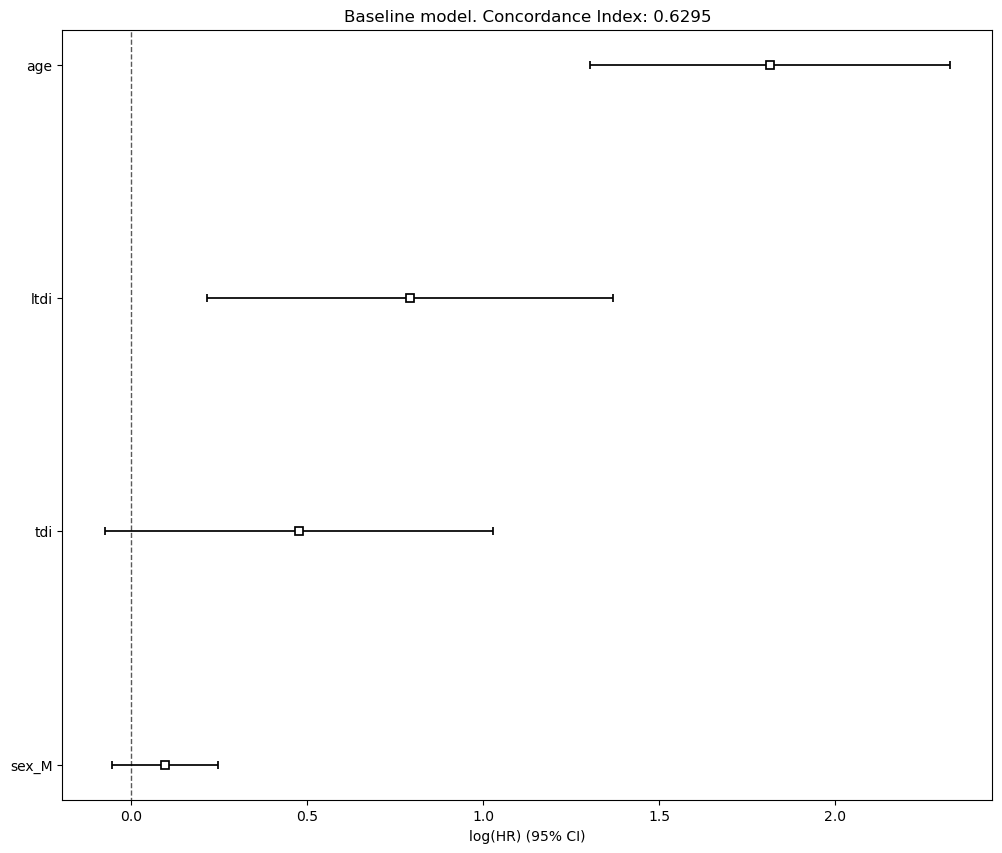

In [61]:
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter


df = DATA.copy()
# columns_to_drop = ["ltdi", "tdi", "volume", "site", "OS"]
columns_to_drop = ["volume", "site", "OS"]
df = df.drop(columns=columns_to_drop)

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns
numerical_features = numerical_features.drop(["OS (corrected)", "status"])

enc_pipe = EncodingPipeline(df)
X = enc_pipe.fit_transform(numerical_features, categorical_features)

cph = CoxPHFitter(penalizer=0.001)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_title(f"Baseline model. Concordance Index: {cph.concordance_index_:.4f}")

cph.plot(ax = ax)

Concordance Index: 0.6816


<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>
             duration col = 'OS (corrected)'
                event col = 'status'
                penalizer = 0.001
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 863
number of events observed = 705
   partial log-likelihood = -3950.46
         time fit was run = 2026-03-04 15:27:47 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
age        2.62     13.76      0.30            2.04            3.21                7.66               24.69
td_pca0    0.08      1.09      0.13           -0.17            0.34                0.84                1.40
td_pca1    0.54      1.72      0.15            0.25            0.83                1.29                2.30
td_pca2    1.10      3.00      0.23            0.64            1.56                1.90                4.75
td_pca3   -0.13      0.88      0.29           -0.69            0.43                0.50                1.53
td_pca4    0.21      1.24      0.22           -0.21            0.64                0.81                1.89
td_pca5    0.33      1.40      0.26           -0.18            0.85                0.83                2.34
td_pca6    0.42      1.52      0.24           -0.06            0.89                0.94                2.44
td_pca7    0.00      1.00      0.22           -0.42            0.43                0.65                1.54
td_pca8    0.24      1.28      0.31           -0.37            0.86                0.69                2.36
td_pca9   -0.44      0.64      0.29           -1.01            0.13                0.36                1.14
td_pca10   0.27      1.31      0.32           -0.36            0.91                0.69                2.48
td_pca11   1.39      4.01      0.33            0.75            2.03                2.11                7.63
td_pca12   0.18      1.20      0.28           -0.36            0.72                0.70                2.06
td_pca13  -0.06      0.95      0.29           -0.63            0.52                0.53                1.68
td_pca14   0.43      1.53      0.25           -0.07            0.92                0.93                2.51
td_pca15   0.18      1.19      0.28           -0.37            0.72                0.69                2.05
td_pca16  -0.39      0.68      0.27           -0.91            0.14                0.40                1.14
td_pca17   0.54      1.72      0.28           -0.00            1.09                1.00                2.98
td_pca18  -0.35      0.71      0.33           -1.00            0.30                0.37                1.35
td_pca19  -0.31      0.74      0.28           -0.86            0.25                0.42                1.28
td_pca20  -0.26      0.77      0.39           -1.04            0.51                0.36                1.67
td_pca21   0.73      2.08      0.38           -0.02            1.48                0.98                4.41
td_pca22   0.37      1.45      0.40           -0.42            1.17                0.66                3.21
td_pca23   0.40      1.50      0.30           -0.19            0.99                0.83                2.70
td_pca24   0.35      1.42      0.25           -0.13            0.84                0.87                2.32
td_pca25   0.08      1.08      0.34           -0.58            0.74                0.56                2.09
td_pca26  -0.07      0.93      0.32           -0.69            0.55                0.50                1.74
td_pca27   0.46      1.58      0.30           -0.13            1.05                0.87                2.86
td_pca28   0.32      1.38      0.32           -0.31            0.95                0.73                2.59
td_pca29   0.55      1.74      0.33           -0.10            1.21                0.90                3.35
t

<Axes: title={'center': 'PCA, n_components: 100. Concordance Index: 0.6816'}, xlabel='log(HR) (95% CI)'>

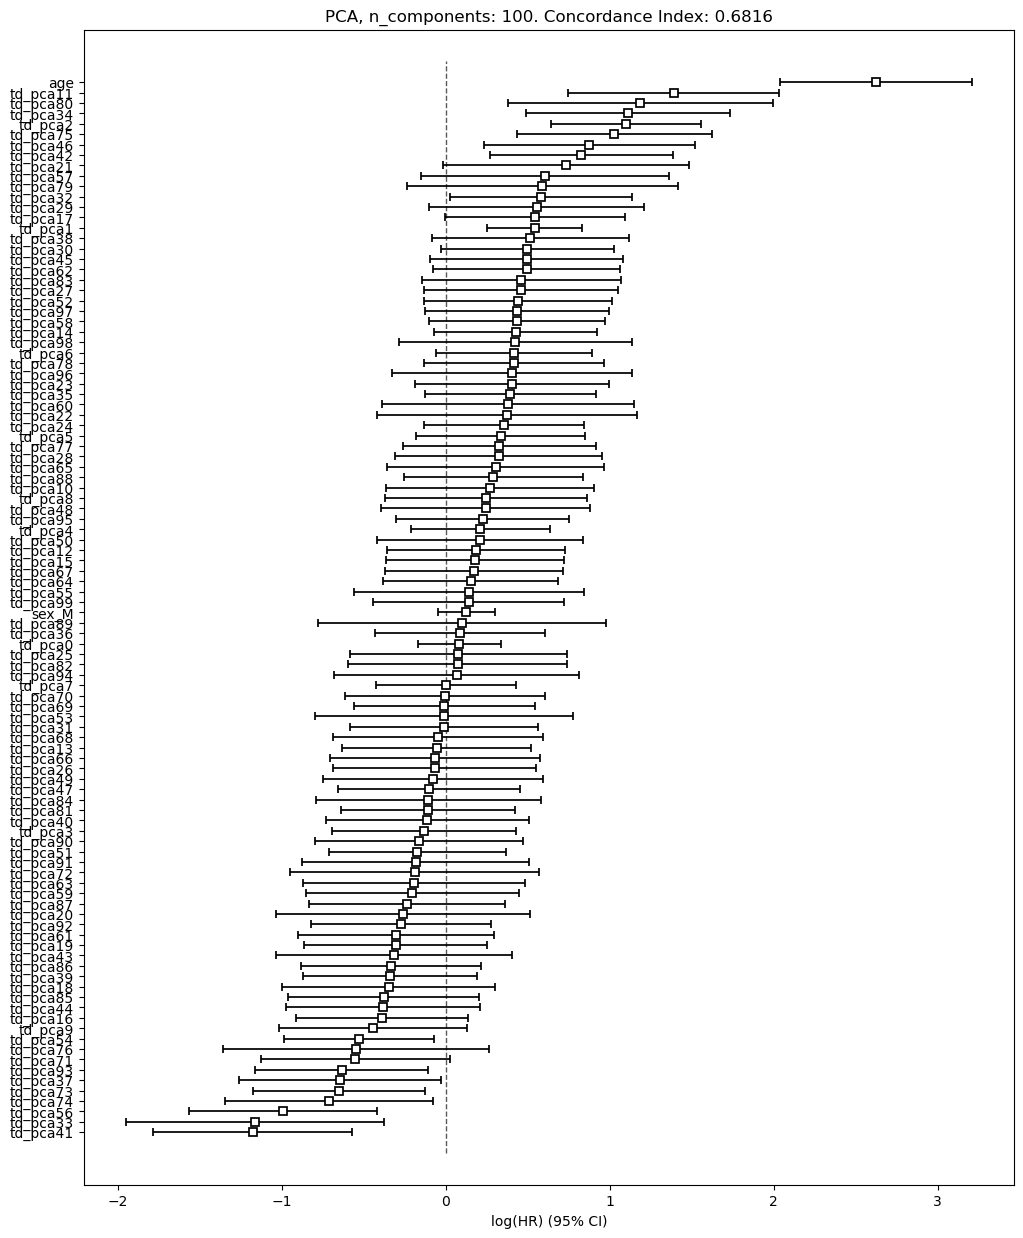

In [78]:
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter


df = data_with_pca
columns_to_drop = ["ltdi", "tdi", "volume", "site", "OS"]
df = df.drop(columns=columns_to_drop)

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns
numerical_features = numerical_features.drop(["OS (corrected)", "status"])

enc_pipe = EncodingPipeline(df)
X = enc_pipe.fit_transform(numerical_features, categorical_features)

cph = CoxPHFitter(penalizer=0.001)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

fig, ax = plt.subplots(figsize=(12, 15))
ax.set_title(f"PCA, n_components: {n_components}. Concordance Index: {cph.concordance_index_:.4f}")

cph.plot(ax = ax)

Concordance Index: 0.6857


<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>
             duration col = 'OS (corrected)'
                event col = 'status'
                penalizer = 0.001
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 863
number of events observed = 705
   partial log-likelihood = -3958.54
         time fit was run = 2026-03-04 15:28:28 UTC

---
              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                     
age           2.52     12.38      0.30            1.94            3.09                6.94               22.08
Cos_Comp_1   -0.01      0.99      0.11           -0.23            0.21                0.79                1.23
Cos_Comp_2    0.44      1.55      0.14            0.17            0.70                1.19                2.02
Cos_Comp_3    0.32      1.38      0.19           -0.05            0.70                0.95                2.01
Cos_Comp_4   -0.24      0.78      0.21           -0.66            0.17                0.52                1.18
Cos_Comp_5   -0.67      0.51      0.23           -1.13           -0.22                0.32                0.80
Cos_Comp_6   -0.72      0.49      0.29           -1.29           -0.15                0.27                0.86
Cos_Comp_7   -0.81      0.44      0.29           -1.39           -0.23                0.25                0.79
Cos_Comp_8    0.09      1.09      0.28           -0.45            0.63                0.64                1.88
Cos_Comp_9   -0.29      0.75      0.30           -0.89            0.30                0.41                1.35
Cos_Comp_10   0.10      1.10      0.37           -0.62            0.82                0.54                2.27
Cos_Comp_11   0.37      1.44      0.45           -0.52            1.26                0.59                3.51
Cos_Comp_12  -0.68      0.50      0.40           -1.46            0.10                0.23                1.10
Cos_Comp_13  -0.51      0.60      0.26           -1.03           -0.00                0.36                1.00
Cos_Comp_14   0.65      1.92      0.33            0.01            1.30                1.01                3.66
Cos_Comp_15  -0.97      0.38      0.40           -1.74           -0.19                0.17                0.83
Cos_Comp_16  -0.36      0.70      0.42           -1.18            0.47                0.31                1.59
Cos_Comp_17   0.12      1.13      0.46           -0.79            1.03                0.45                2.81
Cos_Comp_18   0.27      1.31      0.47           -0.65            1.19                0.52                3.30
Cos_Comp_19   0.17      1.19      0.53           -0.86            1.20                0.42                3.34
Cos_Comp_20  -0.78      0.46      0.53           -1.82            0.26                0.16                1.29
Cos_Comp_21  -0.63      0.53      0.46           -1.53            0.27                0.22                1.31
Cos_Comp_22   0.37      1.45      0.58           -0.77            1.51                0.46                4.55
Cos_Comp_23   0.83      2.28      0.66           -0.47            2.12                0.62                8.36
Cos_Comp_24   0.14      1.15      0.46           -0.76            1.04                0.47                2.83
Cos_Comp_25  -0.84      0.43      0.55           -1.91            0.23                0.15                1.26
Cos_Comp_26   0.80      2.22      0.49           -0.17            1.76                0.85                5.81
Cos_Comp_27   0.44      1.56      0.39           -0.32            1.20                0.73                3.32
Cos_Comp_28  -0.27      0.76      0.78           -1.79            1.25                0.17                3.50
Cos_Comp_29  -1.39      0.25      0.60           -2.57           -0.21                0.08                0.81
Cos_Comp_30  

<Axes: title={'center': 'Cosine Kernel PCA, n_components: 100. Concordance Index: 0.6857'}, xlabel='log(HR) (95% CI)'>

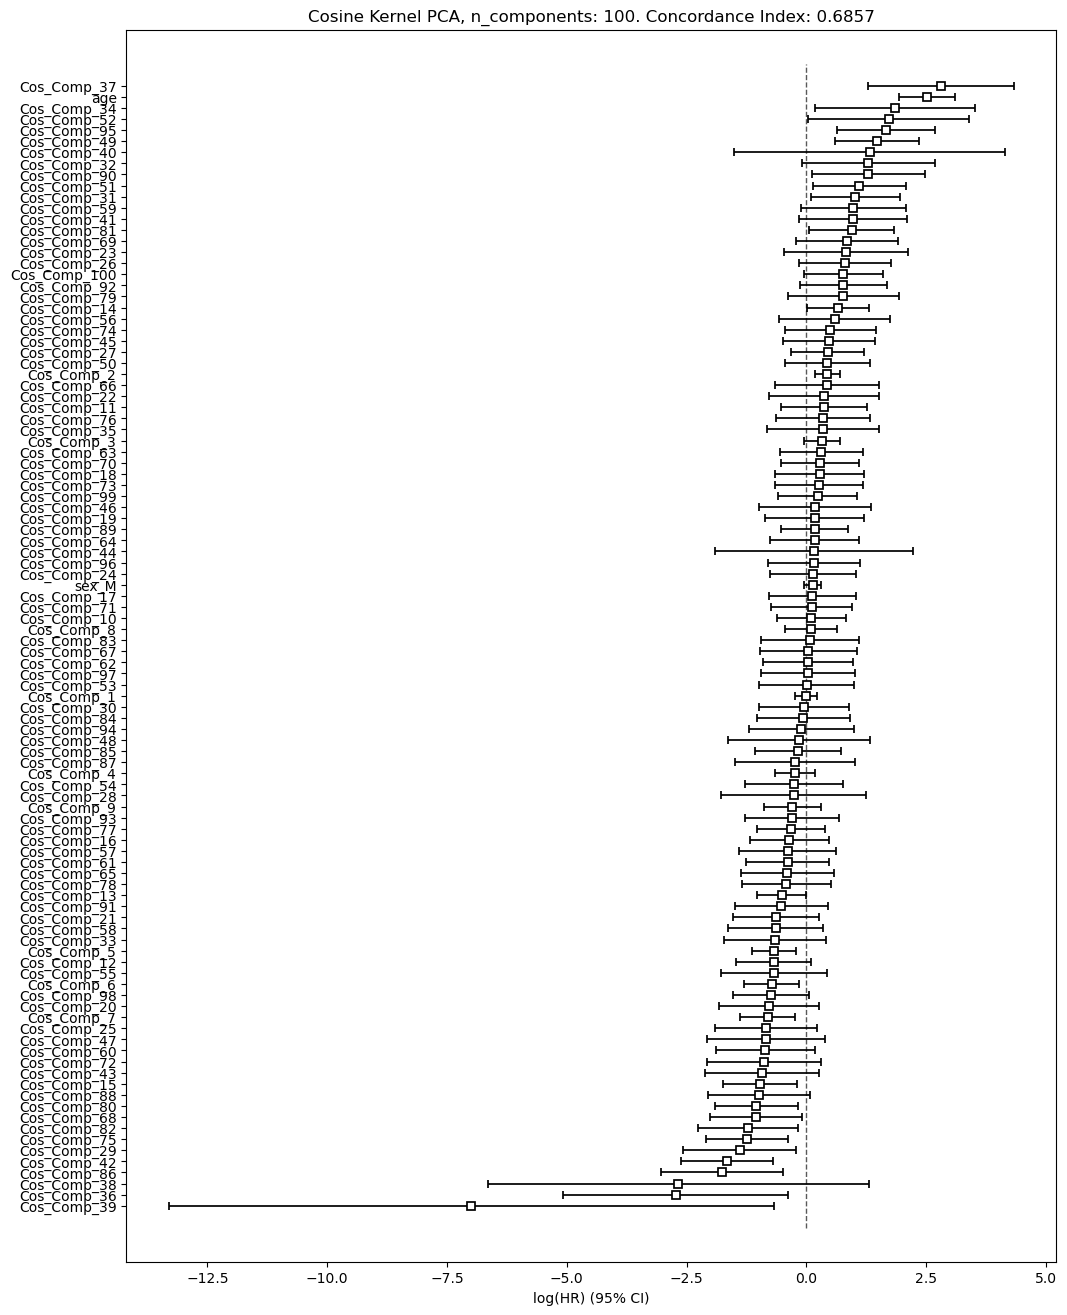

In [80]:
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter


df = data_with_kpca
columns_to_drop = ["ltdi", "tdi", "volume", "site", "OS"]
df = df.drop(columns=columns_to_drop)

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns
numerical_features = numerical_features.drop(["OS (corrected)", "status"])

enc_pipe = EncodingPipeline(df)
X = enc_pipe.fit_transform(numerical_features, categorical_features)

cph = CoxPHFitter(penalizer=0.001)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

fig, ax = plt.subplots(figsize=(12, 16))
ax.set_title(f"Cosine Kernel PCA, n_components: {n_components}. Concordance Index: {cph.concordance_index_:.4f}")

cph.plot(ax = ax)

# NMF

In [ ]:
from nmf_projections import NMFProjections
from nilearn import image, plotting


nmf_proj = NMFProjections(W, H, T1, T1_brain)
output_dir = "results/nmf"
os.makedirs(output_dir, exist_ok=True)
output_filename = "nmf_loadings_4d.nii.gz"

nmf_proj.components_to_brain(
    save_dir=output_dir, 
    filename=output_filename, 
    verbose=True
)

import matplotlib.pyplot as plt
from nilearn import image, plotting

img_path = "results/nmf/nmf_loadings_4d.nii.gz"
n_components = 10

n_cols = 3
n_rows = (n_components + n_cols - 1) // n_cols

fig = plt.figure(figsize=(18, 4 * n_rows))

for i in range(n_components):
    comp_img = image.index_img(img_path, i)
    vmax = comp_img.get_fdata().max()
    
    ax = fig.add_subplot(n_rows, n_cols, i + 1)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"Comp {i} | Max: {vmax:.3f}", 
        threshold=0.01,
        axes=ax, 
        colorbar=True,
        display_mode='z', 
        cut_coords=1,
        annotate=False
    )

plt.subplots_adjust(hspace=0.3, wspace=0.1)
plotting.show()

Concordance Index: 0.6336


<lifelines.CoxPHFitter: fitted with 863 total observations, 158 right-censored observations>
             duration col = 'OS (corrected)'
                event col = 'status'
                penalizer = 0.001
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 863
number of events observed = 705
   partial log-likelihood = -4040.45
         time fit was run = 2026-03-04 15:09:40 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
age          1.90      6.70      0.26            1.39            2.42                4.00               11.24
Cos_Comp_1  -0.00      1.00      0.11           -0.22            0.21                0.80                1.23
Cos_Comp_2   0.34      1.40      0.13            0.08            0.60                1.09                1.81
Cos_Comp_3   0.24      1.28      0.17           -0.09            0.58                0.91                1.79
Cos_Comp_4  -0.25      0.78      0.20           -0.65            0.15                0.52                1.16
Cos_Comp_5  -0.46      0.63      0.20           -0.85           -0.07                0.43                0.93
Cos_Comp_6  -0.57      0.56      0.27           -1.10           -0.04                0.33                0.96
Cos_Comp_7  -0.63      0.53      0.25           -1.12           -0.13                0.33                0.88
Cos_Comp_8   0.13      1.13      0.26           -0.38            0.63                0.69                1.88
Cos_Comp_9  -0.12      0.89      0.27           -0.65            0.41                0.52                1.51
Cos_Comp_10  0.07      1.07      0.35           -0.62            0.75                0.54                2.12
sex_M        0.10      1.10      0.08           -0.06            0.25                0.94                1.28

             cmp to     z      p  -log2(p)
covariate                                 
age            0.00  7.21 <0.005     40.72
Cos_Comp_1     0.00 -0.04   0.97      0.05
Cos_Comp_2     0.00  2.60   0.01      6.77
Cos_Comp_3     0.00  1.42   0.16      2.68
Cos_Comp_4     0.00 -1.23   0.22      2.20
Cos_Comp_5     0.00 -2.30   0.02      5.54
Cos_Comp_6     0.00 -2.11   0.03      4.85
Cos_Comp_7     0.00 -2.48   0.01      6.27
Cos_Comp_8     0.00  0.49   0.62      0.68
Cos_Comp_9     0.00 -0.44   0.66      0.60
Cos_Comp_10    0.00  0.19   0.85      0.24
sex_M          0.00  1.22   0.22      2.17
---
Concordance = 0.63
Partial AIC = 8104.89
log-likelihood ratio test = 83.43 on 12 df
-log2(p) of ll-ratio test = 40.00

<Axes: title={'center': 'Cosinus Kernel PCA. Concordance Index: 0.6336'}, xlabel='log(HR) (95% CI)'>

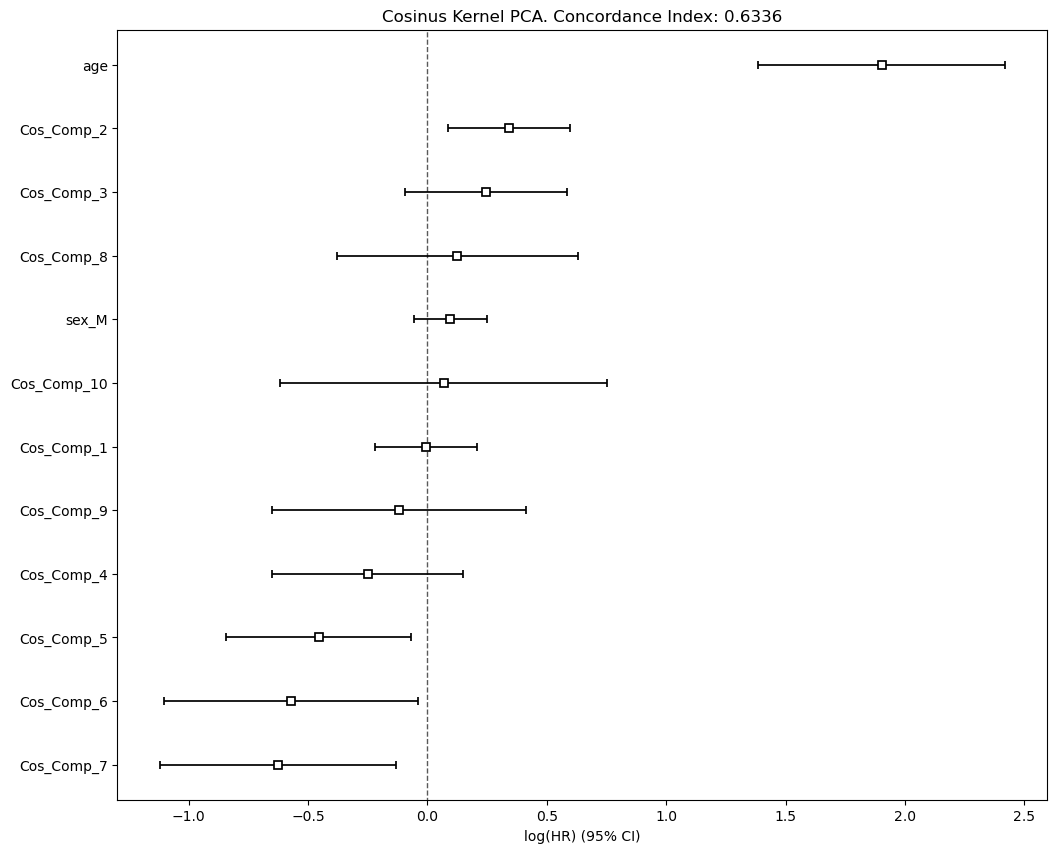

In [44]:
from pipeline_encoder import EncodingPipeline
from lifelines import CoxPHFitter


df = data_with_kpca
columns_to_drop = ["ltdi", "tdi", "volume", "site", "OS"]
df = df.drop(columns=columns_to_drop)

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns
numerical_features = numerical_features.drop(["OS (corrected)", "status"])

enc_pipe = EncodingPipeline(df)
X = enc_pipe.fit_transform(numerical_features, categorical_features)

cph = CoxPHFitter(penalizer=0.001)
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_title(f"Cosinus Kernel PCA. Concordance Index: {cph.concordance_index_:.4f}")

cph.plot(ax = ax)

In [52]:
from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA


normalization = None#'min_max'
save_dir = "results2/"

TD_pca = TD_Kernel_PCA(maps_ucsf, T1, binary_mask=T1_brain, n_components=10, kernel='cosine')
cmps_ucsf = TD_pca.fit_pca_maps(norm=normalization)
# thresholds = TD_pca.explained_variance_plot(save_dir=save_dir, filename=f'{normalization}_normalized_masked.pdf')

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!


In [53]:
from sklearn.decomposition import KernelPCA
import numpy as np

# 2. Obliczasz wariancję z wyników (składowych)
variances = np.var(cmps_ucsf, axis=0)

# 3. Ręcznie wstrzykujesz atrybuty, których szuka funkcja plotująca
TD_pca.explained_variance_ = variances
TD_pca.explained_variance_ratio_ = variances / np.sum(variances)

In [54]:
thresholds = TD_pca.explained_variance_plot(save_dir=save_dir, filename=f'{normalization}_normalized_masked.pdf')

In [55]:
# Sprawdź wartości własne bezpośrednio
lambdas = TD_pca.eigenvalues_ 

# Oblicz ratio na podstawie wartości własnych
explained_variance_ratio = lambdas / np.sum(lambdas)
cumulative_variance = np.cumsum(explained_variance_ratio)
cumulative_variance

array([0.36724351, 0.61748845, 0.73079015, 0.79861833, 0.8554181 ,
       0.89249331, 0.92603366, 0.95390095, 0.98132748, 1.        ])

In [56]:
lambdas

array([71.88098079, 48.98072085, 22.17666872, 13.27608434, 11.1174829 ,
        7.25677169,  6.56489144,  5.45449491,  5.36822431,  3.65479398])

In [58]:
import numpy as np

# 1. Masz już swój model (transformer) i dane (X)
# X_transformed = transformer.fit_transform(X)

# 2. Obliczamy korelacje (zastępstwo dla wag komponentów)
# Chcemy sprawdzić związek: [Komponenty] x [Oryginalne Cechy/Voksele]
# Używamy iloczynu macierzowego dla szybkości (zamiast pętli)

# Najpierw centrujemy dane (ważne dla poprawnej korelacji)
X_centered = maps_ucsf - np.mean(maps_ucsf, axis=0)
scores_centered = cmps_ucsf - np.mean(cmps_ucsf, axis=0)

# Obliczamy macierz wag (n_components, n_features)
# To jest matematyczne przybliżenie tego, co PCA trzyma w .components_
fake_components = np.dot(scores_centered.T, X_centered) / (maps_ucsf.shape[0] - 1)

# 3. "Wstrzykujemy" atrybut do obiektu transformer
TD_pca.components_ = fake_components
TD_pca.n_components_ = cmps_ucsf.shape[1]

In [63]:
import numpy as np

# 1. Pobierz wymiary bezpośrednio z szablonu, który jest w Twoim obiekcie PCA
# To zapobiegnie błędowi ValueError przy reshape
spatial_shape = TD_pca.template.shape[:3] 
n_voxels_in_template = np.prod(spatial_shape)
n_voxels_in_pca = fake_components.shape[1]

print(f"DEBUG: Szablon ma {n_voxels_in_template} voksli, a PCA ma {n_voxels_in_pca}")

# 2. Jeśli liczby się nie zgadzają, musimy sprawdzić czy Twoje PCA nie ma 
# przypadkiem o 1 wymiar za dużo/za mało (np. n_components)
if n_voxels_in_pca != n_voxels_in_template:
    print("UWAGA: Kształty nadal się nie zgadzają. Próbuję dopasować...")
    # Tutaj sprawdzamy, czy fake_components nie jest transponowane
    if fake_components.shape[0] == n_voxels_in_template:
        fake_components = fake_components.T

# 3. Usuwamy maskę, żeby pominąć wadliwy unmasking w bibliotece
if hasattr(TD_pca, "mask_flat"):
    del TD_pca.mask_flat

# 4. Inicjalizacja projektu
Project = Projections(TD_pca)

# 5. RĘCZNY RESHAPE (Kluczowy moment)
# Składamy płaski wektor w kostkę 3D (x, y, z) dla każdego z 10 komponentów
try:
    # Zmieniamy na (10, x, y, z)
    comp_3d = fake_components.reshape((TD_pca.n_components_,) + spatial_shape)
    # Przesuwamy komponenty na koniec: (x, y, z, 10) - tak musi być dla NIfTI
    Project._components_4d = np.transpose(comp_3d, (1, 2, 3, 0))
    print("SUKCES: Kształt 4D ustawiony poprawnie.")
except ValueError as e:
    print(f"BŁĄD KRYTYCZNY: Nie można dopasować {n_voxels_in_pca} do {spatial_shape}. Sprawdź wymiary danych wejściowych!")
    raise e

# 6. Zapis
Project.components_to_brain(save_dir="results2/", filename="final_components.nii.gz")

DEBUG: Szablon ma 1068592 voksli, a PCA ma 1068592
SUKCES: Kształt 4D ustawiony poprawnie.
Kształt Twoich komponentów: (98, 116, 94, 10)
Kształt szablonu (3D): (98, 116, 94)
Liczba voksli w pełnej kostce szablonu: 1068592


ValueError: cannot reshape array of size 10685920 into shape (98,98,116,94)

In [64]:
import os
import nibabel as nib

# 1. Definiujemy ścieżkę zapisu
save_dir = "results2/"
filename = "final_components.nii.gz"
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, filename)

# 2. Przygotowujemy dane (Project._components_4d ma już kształt 98x116x94x10)
# Pobieramy affine i header z szablonu, który jest w PCA
affine = TD_pca.template.affine
header = TD_pca.template.header

# 3. Tworzymy obiekt NIfTI bezpośrednio z naszych gotowych danych
# Używamy ._components_4d, bo tam już siedzi poprawny sześcian
comp_img = nib.Nifti1Image(Project._components_4d, affine=affine, header=header)

# 4. Zapisujemy na dysk
nib.save(comp_img, save_path)

print(f"SUKCES! Plik został zapisany w: {save_path}")

SUKCES! Plik został zapisany w: results2/final_components.nii.gz


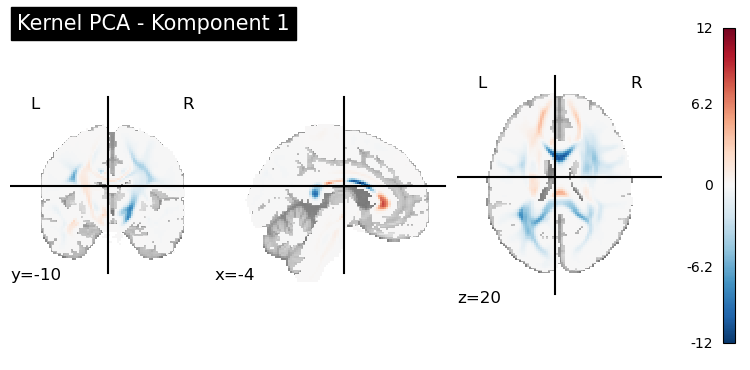

In [71]:
from nilearn import plotting, image

# Wczytaj swój zapisany plik
img = image.load_img("results2/final_components.nii.gz")

# Wybierz np. pierwszy komponent (indeks 0)
first_comp = image.index_img(img, 6)

# Narysuj go na tle standardowego mózgu
plotting.plot_stat_map(first_comp, title="Kernel PCA - Komponent 1", display_mode='ortho')
plotting.show()

In [62]:
import numpy as np

# 1. Obliczamy nasze "fake_components" (korelację)
# Upewnij się, że używasz wycentrowanych danych
X_centered = maps_ucsf - np.mean(maps_ucsf, axis=0)
scores_centered = cmps_ucsf - np.mean(cmps_ucsf, axis=0)
# Macierz (10, 1068592)
fake_components = np.dot(scores_centered.T, X_centered).T / (maps_ucsf.shape[0] - 1)
# Uwaga: sklearn oczekuje (n_components, n_features), więc robimy .T
fake_components = fake_components.T 

# 2. Wstrzykujemy atrybuty do obiektu PCA
TD_pca.components_ = fake_components
TD_pca.n_components_ = fake_components.shape[0]

# --- KLUCZOWA POPRAWKA ---
# Usuwamy tymczasowo mask_flat z obiektu, żeby funkcja _unmask jej nie dotykała
# bo Twoje dane są już "pełne" (milion voksli)
if hasattr(TD_pca, "mask_flat"):
    old_mask = TD_pca.mask_flat
    del TD_pca.mask_flat # Usuwamy, żeby pominąć linię 63 w components.py

# 3. Inicjalizujemy Projections
Project = Projections(TD_pca)

# 4. Ponieważ pominęliśmy unmasking, musimy ręcznie ustawić kształt 4D
# Ustal wymiary Twojego obrazu (template.shape)
spatial_shape = (91, 109, 91) # Zmień na właściwe, jeśli masz inne!

# Reshape z (10, 1068592) -> (10, 91, 109, 91) -> (91, 109, 91, 10)
comp_4d = fake_components.reshape((TD_pca.n_components_,) + spatial_shape)
Project._components_4d = np.transpose(comp_4d, (1, 2, 3, 0))

# 5. Teraz wywołaj zapis do mózgu
Project.components_to_brain(save_dir="results2/", 
                             filename=f"{normalization}_normalized_masked_loadings.nii.gz")

# Opcjonalnie przywróć maskę do obiektu PCA jeśli jej potrzebujesz później
TD_pca.mask_flat = old_mask

ValueError: cannot reshape array of size 10685920 into shape (10,91,109,91)

In [61]:
Project = Projections(TD_pca)

Project.components_to_brain(save_dir="results2/", filename=f"{normalization}_normalized_masked_loadings.nii.gz")

INFO:	Unmasking PCA loadings.


AttributeError: 'mask_flat' is not defined. Check your binary_mask input.

In [ ]:
import pandas as pd

# 1. Wykonaj transformację
X_transformed = TD_pca.transform(X) # Twoje wyniki (scores)

# 2. Oblicz korelację między oryginałem a wynikami KPCA
# Tworzymy DataFrame, żeby łatwo policzyć korelację kolumn
df_orig = pd.DataFrame(X)
df_kpca = pd.DataFrame(X_transformed)

# Korelacja między 1. komponentem a wszystkimi oryginalnymi cechami
feature_importance = df_orig.corrwith(df_kpca[0])

print("Wpływ cech na 1. komponent:")
print(feature_importance.sort_values(ascending=False))

In [ ]:
from nmf_projections import NMFProjections

nmf_proj = NMFProjections(W, H, T1, T1_brain)
output_dir = "results/nmf"
os.makedirs(output_dir, exist_ok=True)
output_filename = "nmf_loadings_4d.nii.gz"

nmf_proj.components_to_brain(
    save_dir=output_dir, 
    filename=output_filename, 
    verbose=True
)